# Live Lab, Data Analytics with Python

One notebook, end to end, on a basket of fictional tickers (ACME, GLOBEX, INITECH): load and clean, make it store-aware, analyse, and present.

**Run it top to bottom from a clean kernel: Kernel then Restart and Run All.**

> Descriptive analysis of sample data for teaching. Not investment advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

## Levels 1 to 2, load and clean

Read daily prices from the bundled CSV, index by date, handle gaps, and turn prices into returns (the comparable unit).

In [2]:
prices = pd.read_csv("data/prices.csv", parse_dates=["date"], index_col="date")
prices.head()

,ACME,GLOBEX,INITECH
date,,,
2023-01-02,98.9700,51.1800,202.5100
2023-01-03,98.4000,50.6300,199.6800
2023-01-04,97.7800,50.3000,199.7100
2023-01-05,97.8100,50.4900,207.3100
2023-01-06,98.9900,51.1600,193.9800


In [3]:
# clean: order by date, drop empty days, carry the last price over a gap
prices = prices.sort_index().dropna(how="all").ffill()
prices.isna().sum()

ACME       0
GLOBEX     0
INITECH    0
dtype: int64

In [4]:
# returns: percent change, per ticker
returns = prices.pct_change().dropna()
returns.head(3)

,ACME,GLOBEX,INITECH
date,,,
2023-01-03,-0.0058,-0.0107,-0.0140
2023-01-04,-0.0063,-0.0065,0.0002
2023-01-05,0.0003,0.0038,0.0381


## Level 3, store-aware: Parquet + DuckDB

Write the returns to a columnar Parquet file and scan them with an in-process columnar engine, the analyst's fast path. Falls back to pandas if `duckdb`/`pyarrow` are not installed.

In [5]:
try:
    returns.to_parquet("data/returns.parquet")
    import duckdb
    scan = duckdb.sql(
        "select avg(ACME) as ACME, avg(GLOBEX) as GLOBEX, avg(INITECH) as INITECH "
        "from 'data/returns.parquet'"
    ).df()
except Exception as exc:
    print("duckdb/pyarrow not available, using pandas:", exc)
    scan = returns.mean().to_frame().T
scan

,ACME,GLOBEX,INITECH
0,-0.0019,0.0015,0.0018


## Level 4, analytics

Describe the basket, then look at trend and comparison.

In [6]:
# summary: mean return and volatility (annualised with 252 trading days)
summary = pd.DataFrame({
    "mean_return": returns.mean(),
    "volatility": returns.std(),
    "annualized_vol": returns.std() * np.sqrt(252),
}).sort_values("volatility")
summary

,mean_return,volatility,annualized_vol
GLOBEX,0.0015,0.0099,0.1574
ACME,-0.0019,0.0132,0.2096
INITECH,0.0018,0.0202,0.3205


In [7]:
# trend: moving averages, rolling volatility, cumulative return
ticker = "ACME"
ma = pd.DataFrame({
    "price": prices[ticker],
    "sma_20": prices[ticker].rolling(20).mean(),
    "sma_50": prices[ticker].rolling(50).mean(),
})
roll_vol = returns[ticker].rolling(21).std()
cumulative = (1 + returns).cumprod() - 1
cumulative.tail(3)

,ACME,GLOBEX,INITECH
date,,,
2023-12-27,-0.4067,0.4482,0.4495
2023-12-28,-0.3972,0.4439,0.4840
2023-12-29,-0.3979,0.4472,0.5194


In [8]:
# compare: correlation across tickers, and rebased performance (start = 100)
corr = returns.corr()
rebased = prices / prices.iloc[0] * 100
corr

,ACME,GLOBEX,INITECH
ACME,1.0000,-0.0038,-0.0533
GLOBEX,-0.0038,1.0000,-0.0232
INITECH,-0.0533,-0.0232,1.0000


## Level 5, presentation

Three charts, each titled with what it shows: how the basket moves together, how it grew, and one ticker's trend.

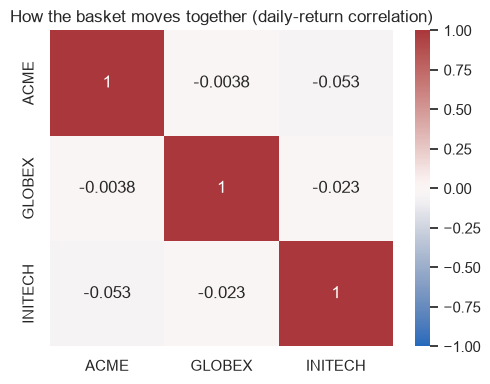

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("How the basket moves together (daily-return correlation)")
plt.tight_layout()
plt.show()

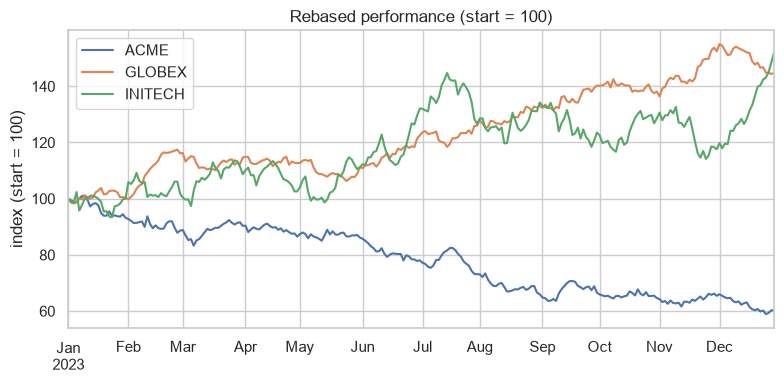

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
rebased.plot(ax=ax)
ax.set_title("Rebased performance (start = 100)")
ax.set_ylabel("index (start = 100)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

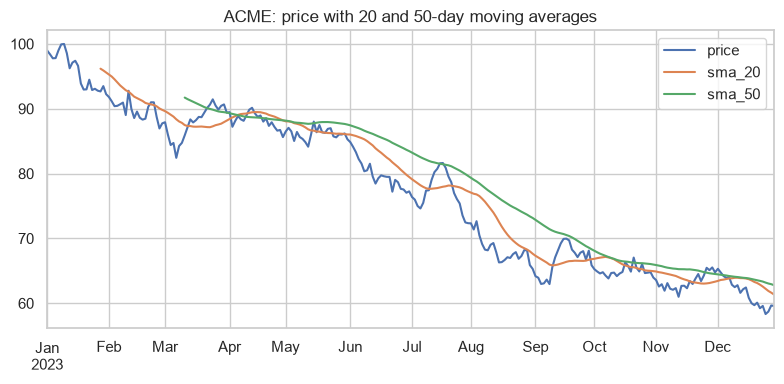

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ma.plot(ax=ax)
ax.set_title(f"{ticker}: price with 20 and 50-day moving averages")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## The finding

_Write the one-paragraph finding here, backed by the charts above._

A good finding names: which ticker grew the most (rebased chart), which was steadiest (lowest volatility in the summary), and whether the three moved together or gave diversification (the correlation heatmap).

> Not investment advice. Descriptive analysis of sample data for teaching.